# 04 - Off-centre zooms, the principal point, stale intrinsics, and a training-free fix

1. **Off-centre crops.** A phone crop or a detection crop is rarely centred. Does alpha
   depend on where we zoom? (50 images per set, KITTI and NYUv2, centre + four quadrants.)
2. **Principal point.** For an off-centre crop the law also moves the principal point.
   Do models that predict intrinsics follow it, or assume it sits in the image centre?
3. **Stale intrinsics.** Metric3D v2 with the unzoomed K: alpha_stale = alpha_true + 1 by
   construction (paper, Sec. 3); here we check the data.
4. **ZoomFix.** When the zoom factor is known (EXIF DigitalZoomRatio, an app's own crop),
   multiplying depth by s**e undoes the shrink. The exponent is chosen leave-one-dataset-out.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import analysis as A
import plotstyle as ps

ps.use()
TAB = ROOT / "outputs/tables"

## 1. Alpha by crop position

where                centre  top-left  top-right  bottom-left  bottom-right
model       dataset                                                        
dav2-s      kitti      1.25      1.98       1.57         0.89          0.88
            nyu        1.03      1.18       1.08         1.00          0.96
depthpro    kitti      0.34      0.60       0.62         0.38          0.36
            nyu        0.42      0.57       0.58         0.42          0.37
moge2-s     kitti      0.44      0.70       0.59         0.10          0.02
            nyu        0.16      0.28       0.31         0.15          0.13
unidepth2-s kitti      0.63      0.88       0.89         0.20          0.17
            nyu        0.14      0.26       0.32         0.07          0.11

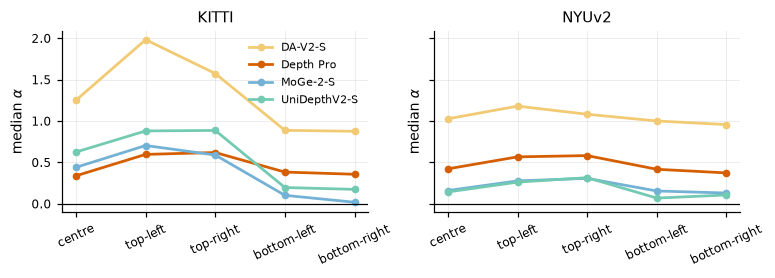

In [2]:
off = A.load("*__offc.csv")
pio = A.per_image(off)
pio["where"] = np.where((pio.cx == 0.5) & (pio.cy == 0.5), "centre",
                        np.where(pio.cy < 0.5, "top", "bottom") + "-" + np.where(pio.cx < 0.5, "left", "right"))
order = ["centre", "top-left", "top-right", "bottom-left", "bottom-right"]
tab = pio.groupby(["model", "dataset", "where"]).alpha.median().unstack("where")[order]
tab.round(3).to_csv(TAB / "offcentre_alpha.csv")
display(tab.round(2))

fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), sharey=True)
for ax, ds in zip(axes, ["kitti", "nyu"]):
    t = tab.xs(ds, level="dataset")
    for m, r in t.iterrows():
        ax.plot(order, r.values, **ps.line(m))
    ax.axhline(0, color="k", lw=0.8)
    ax.set(title=A.PRETTY_DS[ds], ylabel=r"median $\alpha$")
    ax.tick_params(axis="x", rotation=25)
axes[0].legend()
fig.tight_layout()
ps.save(fig, "figS_offcentre_alpha")

## 2. Principal point under off-centre zooms
Error in units of image width. "centred guess" is the error of always answering the
image centre; a model that tracks the law should be well below it.

In [3]:
pp = A.principal_point(off)
if len(pp):
    pp.round(4).to_csv(TAB / "principal_point.csv", index=False)
    q = pp[pp.offset == "quadrant"]
    fig, axes = plt.subplots(1, 2, figsize=(7.2, 2.6), sharey=True)
    for ax, ds in zip(axes, ["kitti", "nyu"]):
        for m in q.model.unique():
            g = q[(q.model == m) & (q.dataset == ds)].sort_values("zoom")
            ax.plot(g.zoom, g.model_error, **ps.line(m))
        g = q[q.dataset == ds].groupby("zoom").centred_guess_error.median()
        ax.plot(g.index, g.values, color="0.4", ls=":", lw=1.2, label="always the centre")
        ax.set(title=A.PRETTY_DS[ds], xlabel="zoom $s$", ylabel="|principal point error| / width")
    axes[0].legend()
    fig.tight_layout()
    ps.save(fig, "figS_principal_point")
    display(q.groupby(["model", "dataset"])[["model_error", "centred_guess_error"]].median().round(3))
else:
    print("no principal-point columns yet (they come with the audit-a2 run)")

no principal-point columns yet (they come with the audit-a2 run)


## 3. Stale K for Metric3D v2

In [4]:
main = A.load()
m3 = A.per_image(main[main.model.isin(["metric3d-s", "metric3d-s-staleK"])])
w = m3.pivot_table(index=["dataset", "name"], columns="model", values="alpha")
diff = (w["metric3d-s-staleK"] - w["metric3d-s"]).dropna()
print(f"alpha(stale) - alpha(true): mean {diff.mean():.4f}, median {diff.median():.4f}, n = {len(diff)}")
stale = A.summary(m3).pivot(index="dataset", columns="model", values=["alpha", "absrel1", "absrel3"])
stale.round(3).to_csv(TAB / "stale_K.csv")
stale.round(3)

alpha(stale) - alpha(true): mean 0.9986, median 1.0000, n = 800


/home/rabeya-noor/Code/zoom-equivariance/src/analysis.py:177: RuntimeWarning: Mean of empty slice
  base2=np.nanmean(g.base2), base3=np.nanmean(g.base3),
/home/rabeya-noor/Code/zoom-equivariance/src/analysis.py:179: RuntimeWarning: All-NaN slice encountered
  fx_err1=np.nanmedian(g.fx_err1)))


alpha                      absrel1                    \
model     metric3d-s metric3d-s-staleK metric3d-s metric3d-s-staleK   
dataset                                                               
diode-in      -0.088             0.912      0.133             0.133   
diode-out     -0.182             0.818      0.276             0.276   
kitti         -0.033             0.967      0.068             0.068   
nyu           -0.107             0.893      0.093             0.093   

             absrel3                    
model     metric3d-s metric3d-s-staleK  
dataset                                 
diode-in       0.477             0.596  
diode-out      0.617             0.621  
kitti          0.093             0.667  
nyu            0.246             0.628

## 4. ZoomFix: a training-free correction when the zoom factor is known

In [5]:
pi = A.per_image(main)
fix = A.zoomfix(pi)
if len(fix):
    fix.round(4).to_csv(TAB / "zoomfix.csv", index=False)
    pooled = fix.groupby("model")[["exponent", "absrel_zoomed", "absrel_fixed", "absrel_unzoomed_same_pixels"]].mean()
    pooled.index = [ps.LABEL.get(m, m) for m in pooled.index]
    display(pooled.round(3))

    fig, ax = plt.subplots(figsize=(7.2, 2.6))
    models = [m for m in fix.model.unique()]
    x = np.arange(len(models))
    wd = 0.27
    g = fix.groupby("model")[["absrel_zoomed", "absrel_fixed", "absrel_unzoomed_same_pixels"]].mean().loc[models]
    ax.bar(x - wd, g.absrel_zoomed, wd, color="0.75", label="3x zoom, as is")
    ax.bar(x, g.absrel_fixed, wd, color=[ps.colour(m) for m in models], label="3x zoom + ZoomFix")
    ax.bar(x + wd, g.absrel_unzoomed_same_pixels, wd, color="none", edgecolor="k", lw=0.8,
           label="unzoomed, same pixels (target)")
    ax.set_xticks(x, [ps.LABEL.get(m, m) for m in models], rotation=20)
    ax.set_ylabel("AbsRel")
    ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, 1.18))
    fig.tight_layout()
    ps.save(fig, "fig6_zoomfix")
else:
    print("no ZoomFix columns yet (they come with the audit-a2 run)")

no ZoomFix columns yet (they come with the audit-a2 run)
